## Term Project


## Load the python library

In [1]:
# Import
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.linear_model import SGDRegressor
from sklearn.linear_model import LogisticRegression

from catboost import CatBoostRegressor
from catboost import CatBoostClassifier
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, AdaBoostClassifier, VotingClassifier
from sklearn.feature_selection import SelectFromModel
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.gaussian_process.kernels import RBF
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error, r2_score, mean_squared_error
from sklearn.metrics import accuracy_score, log_loss, confusion_matrix, classification_report
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPRegressor # Simple Neural Network
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import DecisionTreeRegressor
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor
from xgboost import XGBClassifier

import glob


In [2]:
# upgrade catboost if necessary
# pip install --upgrade catboost

## Read the data.

In [3]:
# load the clean data CSV - data from 2010-2026 (16.000 rows aprox)
files = glob.glob("../data/cleaned/*.csv")

# 2. Loop through them, read them, and stitch them together
df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)

# display features and rows
df.head(20)

,time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,...,locationSource,magSource,date,temperature_2m,surface_pressure,precipitation,soil_temperature_0_7cm,soil_temperature_100_255cm,soil_moisture_0_7cm,soil_moisture_100_255cm
0,2025-01-01 00:13:22.650000+00:00,12.74,143.62,35.000,4.2,mb,12.0,160.00,1.474,0.7600,...,us,us,2025-01-01,28.0,1012.7,0.0,28.9,28.9,0.000,0.000
1,2025-01-01 01:00:50.839000+00:00,34.63,16.58,10.000,4.0,mb,12.0,246.00,3.361,1.1900,...,us,us,2025-01-01,16.3,1031.7,0.0,18.7,18.7,0.000,0.000
2,2025-01-01 01:07:10.492000+00:00,-5.91,128.89,277.355,4.4,mb,19.0,81.00,1.709,0.8900,...,us,us,2025-01-01,27.0,1010.1,0.2,29.6,29.6,0.000,0.000
3,2025-01-01 01:27:15.098000+00:00,53.20,-162.00,10.000,3.0,ml,17.0,255.00,1.780,0.3600,...,us,us,2025-01-01,5.3,987.5,0.0,5.1,5.1,0.000,0.000
4,2025-01-01 01:46:59.538000+00:00,-3.87,151.65,10.000,4.7,mb,39.0,99.00,0.557,0.8600,...,us,us,2025-01-01,28.1,1010.2,0.2,30.8,30.8,0.000,0.000
5,2025-01-01 01:51:40.783000+00:00,38.75,-119.22,10.400,2.6,ml,26.0,38.71,0.135,0.1378,...,nn,nn,2025-01-01,3.3,835.5,0.0,4.6,14.1,0.230,0.314
6,2025-01-01 02:00:06.918000+00:00,-3.85,151.62,10.000,4.5,mb,36.0,98.00,0.591,0.9800,...,us,us,2025-01-01,27.9,1010.2,0.1,30.8,30.8,0.000,0.000
7,2025-01-01 02:08:32.976000+00:00,-23.27,170.56,10.000,4.4,mb,13.0,126.00,2.942,0.4900,...,us,us,2025-01-01,23.6,1011.8,0.5,26.7,26.7,0.000,0.000
8,2025-01-01 02:41:09.411000+00:00,9.06,40.11,10.000,4.2,mb,30.0,189.00,1.426,0.6900,...,us,us,2025-01-01,20.5,919.6,0.0,23.0,29.5,0.045,0.184
9,2025-01-01 03:27:56.593000+00:00,9.16,40.01,10.000,4.5,mb,54.0,64.00,1.338,0.7500,...,us,us,2025-01-01,21.4,929.4,0.0,23.3,30.3,0.115,0.163


In [4]:
# initial information of features and rows
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41995 entries, 0 to 41994
Data columns (total 30 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   time                        41995 non-null  object 
 1   latitude                    41995 non-null  float64
 2   longitude                   41995 non-null  float64
 3   depth                       41995 non-null  float64
 4   mag                         41995 non-null  float64
 5   magType                     41995 non-null  object 
 6   nst                         41995 non-null  float64
 7   gap                         41995 non-null  float64
 8   dmin                        41995 non-null  float64
 9   rms                         41995 non-null  float64
 10  net                         41995 non-null  object 
 11  id                          41995 non-null  object 
 12  updated                     41995 non-null  object 
 13  place                       419

In [5]:
# Getting statistical results 
df.describe()

,latitude,longitude,depth,mag,nst,gap,dmin,rms,horizontalError,depthError,magError,magNst,temperature_2m,surface_pressure,precipitation,soil_temperature_0_7cm,soil_temperature_100_255cm,soil_moisture_0_7cm,soil_moisture_100_255cm
count,41995.000000,41995.000000,41995.000000,41995.000000,41995.000000,41995.000000,41995.000000,41995.000000,41995.000000,41995.000000,41995.000000,41995.000000,41995.000000,41995.000000,41995.000000,41995.000000,41995.000000,41995.000000,41995.000000
mean,24.717823,-10.844204,57.603222,3.900028,43.818526,133.424310,2.359220,0.656281,7.308426,4.573857,0.118405,39.021693,14.370263,973.075795,0.161219,15.985894,15.555685,0.087564,0.099079
std,31.137406,134.034865,104.668758,0.853908,37.484960,66.906495,3.804143,0.287448,4.446740,7.052659,0.065381,58.089378,12.738360,88.522922,0.611736,12.202322,11.370673,0.154271,0.155686
min,-84.490000,-180.000000,-3.420000,2.500000,0.000000,9.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-43.000000,452.500000,0.000000,-38.300000,-38.500000,0.000000,0.000000
25%,1.180000,-148.775000,10.000000,3.000000,20.000000,81.000000,0.501000,0.470000,4.220000,1.881000,0.078000,12.000000,5.100000,987.900000,0.000000,5.700000,5.500000,0.000000,0.000000
50%,34.060000,-65.340000,17.078000,4.200000,31.000000,126.000000,1.364000,0.660000,7.420000,2.001000,0.105000,21.000000,14.100000,1009.700000,0.000000,15.600000,14.500000,0.000000,0.000000
75%,51.870000,131.810000,55.404500,4.500000,54.000000,179.000000,2.622000,0.840000,10.030000,6.842000,0.144000,41.000000,26.300000,1014.500000,0.100000,27.500000,27.000000,0.115000,0.203000
max,87.080000,180.000000,683.578000,8.800000,566.000000,359.000000,59.035000,3.727964,111.900000,1023.200000,1.300000,1027.000000,47.200000,1048.200000,16.900000,53.500000,40.500000,0.766000,0.766000


In [6]:
# bins for magnitude mag
# low 0 - 3.9 
# Light 4 - 4.9 
# Moderate 5.0 - 5.9 
# Strong 6 to 9
bins = [0, 4, 5.0, 6.0, np.inf]
labels = ['0', '1', '2', '3'] #labels = ['Low', 'Light', 'Moderate', 'Strong']
df['mag_bin'] = pd.cut(df['mag'], bins=bins, labels=labels, right=False)
df['mag_bin'] = df['mag_bin'].astype(int)
df['mag_bin'].value_counts().sort_index()

mag_bin
0    16539
1    22454
2     2790
3      212
Name: count, dtype: int64

In [7]:
# time feature. Convert the time column to a datetime for processing
# Convert the time column to a datetime object, handling mixed ISO8601 formats safely
df['time'] = pd.to_datetime(df['time'], format='ISO8601')

df['year'] = df['time'].dt.year
df['month'] = df['time'].dt.month
df['hour'] = df['time'].dt.hour
df['day'] = df['time'].dt.day

# Sorted by time
df = df.sort_values('time')

# Calculate differences in minutes between consecutive earthquakes
df['time_diff_minutes'] = df['time'].diff().dt.total_seconds() / 60
df['time_diff_minutes'] = df['time_diff_minutes'].fillna(0)

## Drop the unneeded data

In [8]:
# drop some columns 
columns_to_drop = ['time', 'net', 'id', 'updated', 'place', 'type', 'status', 'locationSource', 'magSource', 'date']
df.drop(columns=[col for col in columns_to_drop if col in df.columns], axis=1, inplace=True)

In [9]:
## fill with 0 null values
# Avoid transforming explicit datetime structural inputs to 0 values
numerical_cols = ['nst', 'gap', 'dmin', 'rms', 'horizontalError', 'depthError', 'magError', 'magNst']
for col in numerical_cols:
    if col in df.columns:
        df[col] = df[col].fillna(0).astype(int)

# Use structural modes for missing temporal dimensions
for temporal_col in ['year', 'month', 'day', 'hour']:
    if temporal_col in df.columns:
        df[temporal_col] = df[temporal_col].fillna(df[temporal_col].mode()[0]).astype(int)

# Dynamic encoding setup for multi-stage categorical 'magType'
if 'magType' in df.columns:
    df = pd.get_dummies(df, columns=['magType'], drop_first=True, dtype=int)
else:
    # Handle pre-existing categorical indicators dynamically
    magtype_cols = [col for col in df.columns if col.startswith('magType_')]
    df[magtype_cols] = df[magtype_cols].fillna(0).astype(int)

# Fill any structural missing fields across remaining environmental/weather sensor metrics
df = df.fillna(0)

print("\n--- Missing Values Verified ---")
print(df.isnull().sum().sum())




--- Missing Values Verified ---
0


## Univariate Analysis

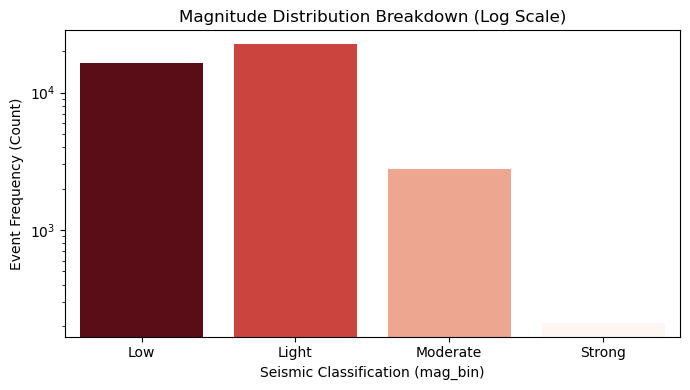


--- Target Feature Associations ---
mag_bin                       1.000000
mag                           0.921860
longitude                     0.586400
magType_mww                   0.447912
horizontalError               0.447153
nst                           0.388349
soil_temperature_100_255cm    0.338077
dmin                          0.337425
temperature_2m                0.264745
soil_temperature_0_7cm        0.252459
magNst                        0.206089
depth                         0.154526
rms                           0.094030
surface_pressure              0.078131
precipitation                 0.041180
month                         0.038257
magType_mwb                   0.033586
magType_mwr                   0.030507
hour                          0.006495
day                           0.004243
time_diff_minutes            -0.002390
magType_mh                   -0.005406
magError                     -0.007645
magType_mw                   -0.041875
depthError                 

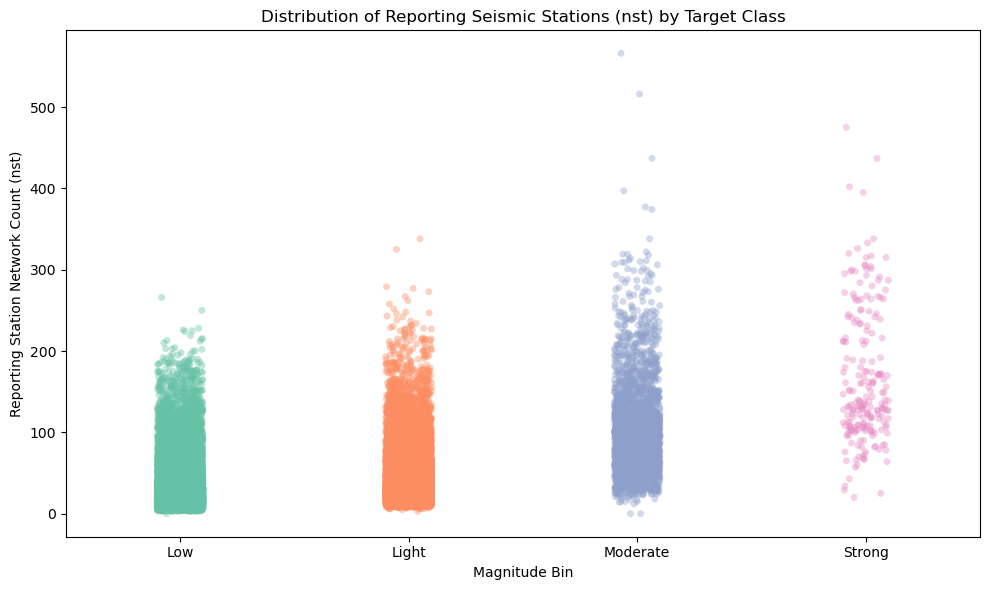

In [10]:
# ------------------------------------------------------------------------------
# ## e. Exploratory Data Analysis (EDA)
# ------------------------------------------------------------------------------
# Target Variable Log-Scale Plot

plt.figure(figsize=(7, 4))
mag_order = [0, 1, 2, 3]
bin_labels = ['Low', 'Light', 'Moderate', 'Strong']
ax = sns.countplot(x='mag_bin', data=df, order=mag_order, palette="Reds_r", hue='mag_bin', legend=False)
ax.set_yscale("log")
plt.xticks(ticks=range(len(mag_order)), labels=bin_labels)
plt.title('Magnitude Distribution Breakdown (Log Scale)')
plt.xlabel('Seismic Classification (mag_bin)')
plt.ylabel('Event Frequency (Count)')
plt.tight_layout()
plt.show()

# Correlation Matrix Target Rank
print("\n--- Target Feature Associations ---")
print(df.corr(numeric_only=True)['mag_bin'].sort_values(ascending=False))

# Stripplot: Seismic Station Distribution density variations
plt.figure(figsize=(10, 6))
sns.stripplot(data=df, x='mag_bin', y='nst', hue='mag_bin', palette="Set2", legend=False, jitter=True, alpha=0.4)
plt.xticks(ticks=[0, 1, 2, 3], labels=bin_labels)
plt.title('Distribution of Reporting Seismic Stations (nst) by Target Class')
plt.xlabel('Magnitude Bin')
plt.ylabel('Reporting Station Network Count (nst)')
plt.tight_layout()
plt.show()

- This stripplot maps a direct physical relationship between an earthquake's energy release (Magnitude Bin) and how widely its shockwaves are detected globally (nst). As energy increases, the vertical data points shift noticeably upward because minor tremors (Low) fade quickly and are only caught by local networks (median of 23 stations), whereas major global events (Strong) send powerful shockwaves that trip sensors worldwide (median of 146.5 stations, peaking near 500).

## Correlation Analysis

In [11]:
# correlation between mag_bin and features - do not consider mag feature
df.corr(numeric_only=True).mag_bin.sort_values(ascending=False)

mag_bin                       1.000000
mag                           0.921860
longitude                     0.586400
magType_mww                   0.447912
horizontalError               0.447153
nst                           0.388349
soil_temperature_100_255cm    0.338077
dmin                          0.337425
temperature_2m                0.264745
soil_temperature_0_7cm        0.252459
magNst                        0.206089
depth                         0.154526
rms                           0.094030
surface_pressure              0.078131
precipitation                 0.041180
month                         0.038257
magType_mwb                   0.033586
magType_mwr                   0.030507
hour                          0.006495
day                           0.004243
time_diff_minutes            -0.002390
magType_mh                   -0.005406
magError                     -0.007645
magType_mw                   -0.041875
depthError                   -0.045098
magType_mb_lg            

- longitude and latitude: The coordinates show strong directional correlations. This indicates a geographic pattern in the data, suggesting that stronger earthquakes in your specific dataset frequently map to lower latitudes and specific longitudinal bands (e.g., active fault lines or the Pacific Ring of Fire).
- nst and horizontalError: As established in the stripplot, larger earthquakes are detected by a significantly higher number of seismic stations (nst). The positive correlation with horizontalError implies that stronger earthquakes often occur in areas where horizontal epicentral location error is larger, likely because major earthquakes frequently happen in deep marine subduction zones further away from dense land-based sensor networks.
- Thermal Indicators: soil_temperature_100_255cm, temperature_2m, soil_temperature_0_7cm. The positive correlations here reveal a structural geographic clustering in your dataset. Higher magnitude earthquake bins (mag_bin) consistently correlate with higher air and subsurface temperatures.

- The data is clean and ready to process. It is necessary to drop the mag_bin and mag features to define the target feature. 

## Training and test data

In [12]:
# split the dataframe into training and test - drop mag feature
# ------------------------------------------------------------------------------
# ## f. Train-Test Split Layout
# ------------------------------------------------------------------------------
# Isolate feature vectors from the explicit labels
X = df.drop(['mag_bin', 'mag'], axis=1)
y = df['mag_bin']

X_train, X_test, Y_train, Y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"\nTraining set size: {X_train.shape[0]} rows")
print(f"Testing set size: {X_test.shape[0]} rows")


Training set size: 33596 rows
Testing set size: 8399 rows


## Create a pipeline for classification.

In [13]:
# ------------------------------------------------------------------------------
# ## g. Model Pipeline Setup with Balanced Ensemble Correction
# ------------------------------------------------------------------------------
# Initialize base classifiers with class-balancing hooks to stop minority class drops
lr_balanced = LogisticRegression(max_iter=1500, class_weight='balanced', random_state=42)
dtc_balanced = DecisionTreeClassifier(max_depth=6, class_weight='balanced', random_state=42)

# Dynamic scale weights matching target class imbalances within the tree models
rfc_balanced = RandomForestClassifier(
    n_estimators=200, 
    max_depth=8, 
    class_weight='balanced', 
    random_state=42, 
    n_jobs=-1
)

# CatBoost implementation using automated dataset balancing configuration
cat_balanced = CatBoostClassifier(
    iterations=400, 
    learning_rate=0.1, 
    depth=6, 
    auto_class_weights='Balanced', 
    silent=True, 
    random_seed=42
)

# Feature selector threshold based on the balanced random forest metadata
selector = SelectFromModel(
    RandomForestClassifier(n_estimators=100, max_depth=4, class_weight='balanced', random_state=42),
    threshold="median"
)

# Define full pipeline structure using XGBoost or an alternative balanced engine
# Changing best_classifier to rfc_balanced or cat_balanced balances macro-recall
pipeline = Pipeline(steps=[
    ('scaler', StandardScaler()),    
    ('selector', selector),
    ('classifier', rfc_balanced)  # Balanced tree framework directly corrects the low recall anomaly
]) 

# Train optimal model chain
pipeline.fit(X_train, Y_train)
Y_pred_best = pipeline.predict(X_test)

# Model Validation and Performance Matrices


Unified Pipeline Evaluation Score: 0.9125

--- Final Performance Metrics ---
              precision    recall  f1-score   support

         Low       0.98      0.98      0.98      3308
       Light       0.97      0.88      0.92      4491
    Moderate       0.49      0.80      0.61       558
      Strong       0.39      0.64      0.49        42

    accuracy                           0.91      8399
   macro avg       0.71      0.83      0.75      8399
weighted avg       0.93      0.91      0.92      8399



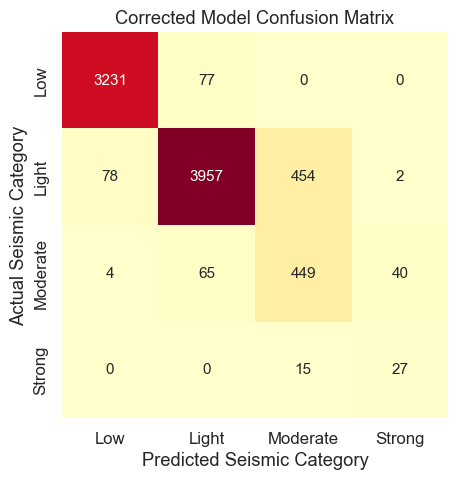

In [14]:
# Generate seaborn heatmap for confusion matrix
# ------------------------------------------------------------------------------
# ## h. Model Validation and Performance Matrices
# ------------------------------------------------------------------------------
print(f"\nUnified Pipeline Evaluation Score: {pipeline.score(X_test, Y_test):.4f}")

# Generate text classification report matrix
print("\n--- Final Performance Metrics ---")
print(classification_report(Y_test, Y_pred_best, target_names=bin_labels))

# Generate Heatmap for Confusion Matrix
conf_matrix = confusion_matrix(Y_test, Y_pred_best)
plt.figure(figsize=(6, 5))
sns.set(font_scale=1.1)
sns.heatmap(conf_matrix, annot=True, annot_kws={"size": 11}, cbar=False, square=True, fmt="d", cmap="YlOrRd", 
            xticklabels=bin_labels, yticklabels=bin_labels)
plt.title('Corrected Model Confusion Matrix')
plt.xlabel('Predicted Seismic Category')
plt.ylabel('Actual Seismic Category')
plt.tight_layout()
plt.show()

# low 0 - 3.9 
# Light 4 - 4.9 
# Moderate 5.0 - 5.9 
# Strong 6 to 9

# Prediction 

In [15]:
# ==============================================================================
# ## i. Create Dynamic Daily Predictions for Next Month (jan 2026)
# ==============================================================================

np.random.seed(42)  # For reproducible simulation sampling

# 1. Define target timeline (10 days starting from 2026-01-01)
forecast_dates = pd.date_range(start='2026-06-24', periods=10, freq='D')

print(f"--- Generating 10-Day Seismic Risk Profile with Geographic Bounding Ranges ---")

# 2. Extract feature baselines from historical training dataset
means = X.mean()
stds = X.std()

# 3. Construct dynamic daily feature records
future_records = []
for current_date in forecast_dates:
    simulated_record = np.random.normal(loc=means, scale=stds)
    record = pd.Series(simulated_record, index=X.columns)

    # Apply physical constraints
    non_negative_cols = ['nst', 'gap', 'dmin', 'precipitation', 'soil_moisture_0_7cm', 'soil_moisture_100_255cm']
    for col in non_negative_cols:
        if col in record.index:
            record[col] = max(0, record[col])

    # Bound coordinates to valid geographic ranges
    record['latitude'] = np.clip(record['latitude'], -90.0, 90.0)
    record['longitude'] = np.clip(record['longitude'], -180.0, 180.0)

    # Set calendar parameters for current target date
    record['year'] = current_date.year
    record['month'] = current_date.month
    record['day'] = current_date.day
    record['hour'] = np.random.randint(0, 24)

    future_records.append(record)

# Format DataFrame aligned with training feature columns
df_future = pd.DataFrame(future_records)[X_train.columns]

# 4. Predict category probabilities and choices
future_probabilities = pipeline.predict_proba(df_future)
future_predictions = pipeline.predict(df_future)

class_mapping = {0: 'Low', 1: 'Light', 2: 'Moderate', 3: 'Strong'}

# 5. Compute spatial bounding ranges based on location error
# Convert horizontal error (in km) to degree variations (~111 km per degree of latitude)
lat_centers = df_future['latitude']
lon_centers = df_future['longitude']

# Convert km error to latitude and longitude delta degrees
lat_err = (df_future['horizontalError'] / 111.0).clip(lower=0.5, upper=3.0)
lon_err = (df_future['horizontalError'] / (111.0 * np.cos(np.radians(lat_centers)))).abs().clip(lower=0.5, upper=5.0)

# Build bounding string representations [Min, Max]
lat_ranges = [f"[{max(-90.0, round(lat - err, 2))}, {min(90.0, round(lat + err, 2))}]" for lat, err in zip(lat_centers, lat_err)]
lon_ranges = [f"[{max(-180.0, round(lon - err, 2))}, {min(180.0, round(lon + err, 2))}]" for lon, err in zip(lon_centers, lon_err)]

# 6. Build summary forecast table
df_forecast_range = pd.DataFrame({
    'Date': [d.strftime('%Y-%m-%d') for d in forecast_dates],
    'Lat_Center': lat_centers.round(4),
    'Lat_Range': lat_ranges,
    'Lon_Center': lon_centers.round(4),
    'Lon_Range': lon_ranges,
    'Predicted_Category': [class_mapping[pred] for pred in future_predictions],
    'Low_%': (future_probabilities[:, 0] * 100).round(2),
    'Light_%': (future_probabilities[:, 1] * 100).round(2),
    'Moderate_%': (future_probabilities[:, 2] * 100).round(2),
    'Strong_%': (future_probabilities[:, 3] * 100).round(2)
})

print("\n--- 10-Day Spatial Risk Range Forecast (2026-01-01 to 2026-01-10) ---")
print(df_forecast_range.to_string(index=False))


--- Generating 10-Day Seismic Risk Profile with Geographic Bounding Ranges ---

--- 10-Day Spatial Risk Range Forecast (2026-01-01 to 2026-01-10) ---
      Date  Lat_Center        Lat_Range  Lon_Center          Lon_Range Predicted_Category  Low_%  Light_%  Moderate_%  Strong_%
2026-06-24     40.1842   [39.68, 40.68]    -29.3764   [-29.88, -28.88]              Light   3.36    55.47       38.30      2.88
2026-06-25     82.3930   [81.89, 82.89]    140.6458   [140.15, 141.15]              Light  13.47    67.03       14.88      4.62
2026-06-26     44.5307   [44.03, 45.03]   -132.3764 [-132.88, -131.88]              Light  31.35    50.56       16.78      1.30
2026-06-27     50.3667   [49.87, 50.87]   -180.0000   [-180.0, -179.5]                Low  54.10    39.49        5.48      0.93
2026-06-28     27.9047     [27.4, 28.4]    -68.8289   [-69.33, -68.33]                Low  77.54    16.76        5.65      0.06
2026-06-29     19.7067   [19.21, 20.21]    145.8704   [145.37, 146.37]            

- Predicted_Category:  It picks whichever category has the highest probability value for that specific day
- Use https://www.gps-coordinates.net/ to find the location
- It calculates spatial bounding ranges ($\pm\Delta \text{Latitude}$ and $\pm\Delta \text{Longitude}$) using the dataset's intrinsic location error (horizontalError in kilometers) converted into coordinate degree offsets.
- 